# Paper 3 — Statistical Effect Sizes & Hypothesis Testing (H1 to H4)

This notebook generates publication-ready figures displaying effect sizes (standardized betas and Cohen's $d$) with 95% confidence intervals and FDR significance markers (* $q < 0.05$).

### Structure:
- **Layer 1: Config** (Paths, directories, plot styling, labels, palettes)
- **Layer 2: Load** (Load statistical results from `output/statistical_analysis/results_H1-4.csv`)
- **Layer 3: Define** (Helper plotting functions for Forest plots across H1, H2, H3, H4, and Synthesis Overview)
- **Layer 4: Run & Save** (Execute plots and save high-resolution 300 DPI figures to `output/Figures/`)


In [1]:
# =============================================================================
# LAYER 1: CONFIGURATION & STYLING
# =============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t as student_t

# File Paths
PROJECT_ROOT = Path(r"C:\Users\pandya\Documents\Github\docker\Paper3_Final")
RESULTS_CSV  = PROJECT_ROOT / "output" / "statistical_analysis" / "results_H1-4.csv"
H4_MULTI_CSV = PROJECT_ROOT / "output" / "statistical_analysis" / "H4_Multivariable_CoExposure.csv"
OUT_DIR      = PROJECT_ROOT / "output" / "Figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MATCHED_DURATION_LABEL = "Matched_start_8min"

# Standardised Colour Palettes
PHASE_COLORS = {
    "BikeU": "#d45500",   # dark orange
    "WalkU": "#b8860b",   # dark goldenrod / sepia-gold
    "BikeG": "#1a6b1a",   # dark green
    "WalkG": "#52b852",   # medium green
    "Tram":  "#7f8c8d",   # grey
}
ENV_COLORS = {"Urban": "#ffbb00", "Green": "#27ae60", "Tram": "#7f8c8d"}
ENV_ORDER  = ["Urban", "Tram", "Green"]
MODE_COLORS = {"Bike": "#d72806", "Walk": "#1a6b1a", "Sit": "#7f8c8d"}
MODE_ORDER  = ["Sit", "Bike", "Walk"]
PARTICIPANT_COLORS = {
    "P2": "#e63946", "P3": "#2a9d8f", "P4": "#264653",
    "P5": "#e76f51", "P6": "#457b9d", "P7": "#6a4c93",
    "P8": "#1d3557", "P9": "#f4a261", "P10": "#2d6a4f",
    "P11": "#c1121f", "P12": "#780000", "P13": "#3a86ff",
    "P14": "#8338ec", "P15": "#fb5607", "P16": "#005f73",
    "P17": "#606c38", "P18": "#bc6c25",
}

# Forest plot aesthetic tones
COLOR_SIG   = "#c0392b"  # Brick red for FDR-significant effects
COLOR_NS    = "#7f8c8d"  # Muted grey for non-significant effects
COLOR_BIKE  = "#d45500"  # Dark orange for Bike
COLOR_WALK  = "#1a6b1a"  # Dark green for Walk

# Clean Display Labels
LABEL_MAP = {
    # Psychological Surveys
    "questionnaire_current_comfort_1_7":   "General Comfort (1-7)",
    "questionnaire_pleasantness_1_5":      "Pleasantness (1-5)",
    "questionnaire_stai6_mean_1_5":        "State Anxiety (STAI-6)",
    "questionnaire_prs11_total_mean_1_5":  "Restorativeness (PRS-11)",
    
    # Empatica Empatica (Autonomic Physiology)
    "empatica_heart_rate":                 "Heart Rate (bpm)",
    "empatica_eda_tonic":                  "EDA Tonic Level (SCL)",
    "empatica_eda_phasic":                 "EDA Phasic (SCR)",
    "empatica_skin_temperature":           "Skin Temperature (°C)",
    "empatica_hrv_td_sdnn":                "HRV (SDNN)",
    "empatica_hrv_td_rmssd":               "HRV (RMSSD)",
    "empatica_hrv_fd_lf":                  "HRV LF Power",
    "empatica_hrv_fd_hf":                  "HRV HF Power",
    "empatica_hrv_fd_lf_hf_ratio":         "HRV LF/HF Ratio",
    "empatica_hrv_fd_lfnu":                "HRV LFnu",
    "empatica_hrv_fd_hfnu":                "HRV HFnu",
    "empatica_hrv_fd_vlf":                 "HRV VLF Power",
    "empatica_hrv_fd_total_power":         "HRV Total Power",
    
    # Eyetracker Neon (Eye Tracking / Ocular)
    "eyetracker_pupil_diameter_avg":       "Pupil Diameter (mm)",
    "eyetracker_pupil_change_rate":        "Pupil Change Rate",
    "eyetracker_blink_duration_s":         "Blink Duration (s)",
    "eyetracker_fixation_duration_s":      "Fixation Duration (s)",
    "eyetracker_fixation_rate":            "Fixation Rate (/s)",
    "eyetracker_saccade_duration_s":       "Saccade Duration (s)",
    "eyetracker_saccade_amplitude":        "Saccade Amplitude (°)",
    "eyetracker_saccade_peak_velocity":    "Saccade Peak Velocity (°/s)",
    "eyetracker_gaze_velocity":            "Gaze Velocity (°/s)",
    "eyetracker_gaze_dispersion":          "Gaze Dispersion",
    "eyetracker_gaze_centrality":          "Gaze Centrality",
    "eyetracker_distance_from_center":     "Gaze Distance from Center (px)",
    "eyetracker_eyelid_aperture_avg":      "Eyelid Aperture (mm)",
    
    # Environmental & Urban Predictor Streams - Explicit Sensor Platform Designation
    # Ucm Backpack: Thermal & Microclimatic
    "ucm_PET":                             "Ucm: PET Thermal Index (°C)",
    "ucm_PET_SR":                          "Ucm: PET (Solar Radiation, °C)",
    "ucm_UTCI":                            "Ucm: UTCI Thermal Index (°C)",
    "ucm_UTCI_SR":                         "Ucm: UTCI (Solar Radiation, °C)",
    "ucm_AIR_temp":                        "Ucm: Air Temperature (°C)",
    "ucm_AIR_RH":                          "Ucm: Relative Humidity (%)",
    "ucm_AIR_T_bot":                       "Ucm: Air Temp Bottom (°C)",
    "ucm_AIR_T_mid":                       "Ucm: Air Temp Middle (°C)",
    "ucm_AIR_T_top":                       "Ucm: Air Temp Top (°C)",
    "ucm_AH":                              "Ucm: Absolute Humidity (g/m³)",
    "ucm_HUMIDEX":                         "Ucm: Humidex Thermal Index",
    "ucm_HUMIDEX_SR":                      "Ucm: Humidex (Solar Radiation)",
    "ucm_MRT":                             "Ucm: Mean Radiant Temp (°C)",
    "ucm_MRT_S":                           "Ucm: Mean Radiant Temp (Solar, °C)",
    "ucm_OPT":                             "Ucm: Operative Temp (°C)",
    "ucm_WIND_AWA":                        "Ucm: Apparent Wind Angle (°)",
    "ucm_WIND_AWS":                        "Ucm: Apparent Wind Speed (m/s)",
    "ucm_WIND_TWD":                        "Ucm: True Wind Direction (°)",
    "ucm_WIND_TWS":                        "Ucm: True Wind Speed (m/s)",
    
    # Ucm Backpack: Solar, Radiation & Kinematics
    "ucm_SUN_Gh":                          "Ucm: Global Solar Rad (W/m²)",
    "ucm_SUN_alt":                         "Ucm: Sun Altitude (°)",
    "ucm_SUN_az":                          "Ucm: Solar Azimuth (°)",
    "Clearness_Index":                     "Ucm: Clearness Index (kt)",
    "ucm_IR_up":                           "Ucm: Thermal Radiation Up (W/m²)",
    "ucm_IR_down":                         "Ucm: Thermal Radiation Down (W/m²)",
    "ucm_IR_front":                        "Ucm: Thermal Radiation Front (W/m²)",
    "ucm_IR_back":                         "Ucm: Thermal Radiation Back (W/m²)",
    "ucm_IR_left":                         "Ucm: Thermal Radiation Left (W/m²)",
    "ucm_IR_right":                        "Ucm: Thermal Radiation Right (W/m²)",
    "ucm_IR_spot_sky":                     "Ucm: IR Surface Temp Sky (°C)",
    "ucm_IR_spot_gnd":                     "Ucm: IR Surface Temp Ground (°C)",
    "ucm_IR_spot_left":                    "Ucm: IR Surface Temp Left (°C)",
    "ucm_IR_spot_right":                   "Ucm: IR Surface Temp Right (°C)",
    "ucm_SND_dBA":                         "Ucm: Acoustic Noise (dBA)",
    "ucm_GPS_speed_kmh":                   "Ucm: Speed (km/h)",
    "ucm_GPS_alt":                         "Ucm: Altitude (m)",
    "ucm_GPS_hdg":                         "Ucm: GPS Heading (°)",
    "ucm_MAG_hdg":                         "Ucm: Magnetic Heading (°)",
    "ucm_GPS_HDOP":                        "Ucm: GPS HDOP",
    
    # Atmotube (Averaged Researcher Left & Right)
    "atmo_pm1.0_avg":                      "Atmotube: PM1.0 (µg/m³)",
    "atmo_pm2.5_avg":                      "Atmotube: PM2.5 (µg/m³)",
    "atmo_pm10_avg":                       "Atmotube: PM10 (µg/m³)",
    "atmo_temperature_avg":                "Atmotube: Air Temp (°C)",
    "atmo_humidity_avg":                   "Atmotube: Relative Humidity (%)",
    
    # LYS Button (Averaged Participant LYS1 & Researcher LYS2)
    "lys_lux_avg":                         "LYS: Illuminance (lux)",
    "lys_rgbb_avg":                        "LYS: Blue Irradiance (rgbb)",
    "lys_rgbg_avg":                        "LYS: Green Irradiance (rgbg)",
    "lys_rgbr_avg":                        "LYS: Red Irradiance (rgbr)",
    "lys_kelvin_avg":                      "LYS: Color Temperature (K)",
    "lys_medi_avg":                        "LYS: Melanopic EDI (medi)",
    
    # GVI (Eye-Level 360° Visual Greenness)
    "gvi_50m":                             "GVI: Green View Index (50m)",
    "gvi_tree_50m":                        "GVI: Tree Canopy (50m)",
    "gvi_grass_50m":                       "GVI: Grass View Index (50m)",
    "gvi_plant_50m":                       "GVI: Total Plant View Index (50m)",
    "gvi_point_gvi":                       "GVI: Point Green View Index",
    "gvi_point_tree":                      "GVI: Point Tree Canopy",
    "gvi_phase_mean":                      "GVI: Phase Mean GVI",
    "tree_phase_mean":                     "GVI: Phase Mean Tree Canopy",
    
    # YAMNet (Deep Learning Sound Event Classification)
    "sound_prop_vehicle":                  "YAMNet: Vehicle Sound Prop",
    "sound_prop_urban_manmade_positive":   "YAMNet: Urban/Manmade Positive Sound Prop",
    "sound_prop_urban_manmade_neutral":    "YAMNet: Urban/Manmade Neutral Sound Prop",
    "sound_prop_urban_manmade_negative":  "YAMNet: Urban/Manmade Negative Sound Prop",
    "sound_prop_rural_natural":            "YAMNet: Natural Sound Prop",
    "sound_prop_wind":                     "YAMNet: Wind Sound Prop",
    "sound_prop_mechanisms":               "YAMNet: Machinery Sound Prop",
    "sound_prop_unidentify":               "YAMNet: Unidentified Sound Prop",
    "sound_level_dbfs":                    "YAMNet: Audio Level (dBFS)",
}

# Configure Matplotlib styling
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
print("Layer 1 Configured successfully. Outputs will be saved to:", OUT_DIR)





Layer 1 Configured successfully. Outputs will be saved to: C:\Users\pandya\Documents\Github\docker\Paper3_Final\output\Figures


In [2]:
# =============================================================================
# LAYER 2: DATA LOADING & PREPARATION
# =============================================================================
df_raw = pd.read_csv(RESULTS_CSV)

# Ensure numeric columns are properly parsed
numeric_cols = ["Estimate_SD", "SE", "Beta_Std", "Beta_Within_Std", "Cohens_d_LMM", "CI95_low", "CI95_high", "p_value", "q_FDR"]
for col in numeric_cols:
    if col in df_raw.columns:
        df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

# Standardize FDR boolean
df_raw["is_sig"] = df_raw["FDR_significance"].astype(str).str.lower().isin(["true", "1", "yes"])

# Figures must use exactly the same duration as statistical_analysis.R.
loaded_durations = set(df_raw["Duration"].dropna().astype(str))
if loaded_durations != {MATCHED_DURATION_LABEL}:
    raise ValueError(
        f"Figure source contains non-matched duration(s): {sorted(loaded_durations)}. "
        f"Expected only {MATCHED_DURATION_LABEL}. Rerun statistical_analysis.R first."
    )

# Primary analysis: Within-Person Z-score only in the matched 8-minute data.
# Indoor- and Tram-baseline branches are not part of the primary analysis.
PRIMARY_NORMALIZATION = "Within-Person Z-score"
loaded_normalizations = set(df_raw["Normalization"].dropna().astype(str))
if loaded_normalizations != {PRIMARY_NORMALIZATION}:
    raise ValueError(
        f"Figure source contains non-primary normalization(s): {sorted(loaded_normalizations)}. "
        f"Expected only {PRIMARY_NORMALIZATION}. Rerun statistical_analysis.R first."
    )
df_wpz = df_raw.copy()

print("Loaded total rows:", len(df_raw))
print("Within-Person Z-score FDR-significant models:", df_wpz["is_sig"].sum())




# Load current multivariable co-exposure results (H4.2)
df_h4_multi = pd.read_csv(H4_MULTI_CSV)
for col in ["Beta_Std", "SE", "CI95_low", "CI95_high", "t_stat", "p_value", "q_FDR"]:
    if col in df_h4_multi.columns:
        df_h4_multi[col] = pd.to_numeric(df_h4_multi[col], errors="coerce")
df_h4_multi["is_sig"] = df_h4_multi["FDR_significance"].astype(str).str.lower().isin(["true", "1", "yes"])
h4_multi_predictor_count = df_h4_multi["Predictor"].nunique()
h4_multi_model_count = len(df_h4_multi)
print("Multivariable H4 predictors/models/FDR-significant:", h4_multi_predictor_count, h4_multi_model_count, df_h4_multi["is_sig"].sum())


Loaded total rows: 1364
Within-Person Z-score FDR-significant models: 274
Multivariable H4 predictors/models/FDR-significant: 4 120 11


In [3]:
# =============================================================================
# LAYER 3: HELPER PLOTTING FUNCTIONS
# =============================================================================
def _ci_bounds(frame, estimate_col):
    """Calculate two-sided df-based t intervals for the estimate plotted by each panel."""
    estimate = pd.to_numeric(frame[estimate_col], errors="coerce")
    se = pd.to_numeric(frame["SE"], errors="coerce")
    df = pd.to_numeric(frame["df"], errors="coerce").clip(lower=1)
    critical = pd.Series(student_t.ppf(0.975, df), index=frame.index)
    return estimate - critical * se, estimate + critical * se

def get_sensor_group(outcome_str):
    """Assign sensor/domain rank and label for grouped y-axis ordering."""
    s = str(outcome_str).lower()
    if s.startswith("questionnaire"):
        return (2, "Psychological Surveys")
    elif s.startswith("empatica"):
        return (1, "Empatica")
    elif s.startswith("eyetracker"):
        return (0, "Eyetracker")
    elif s.startswith("ucm") or s.startswith("lys") or s.startswith("atmo"):
        return (3, "Environmental Context")
    return (4, "Other")

def add_sensor_group_labels(ax, sub, bracket_x=-0.42, label_x=-0.54, font_size=8.5, groups=None):
    """Annotates sensor/device domain brackets along the left side of y-axis."""
    if groups is None:
        groups = [
            (0, "Eyetracker", "#1e3a8a"),
            (1, "Empatica", "#0f766e"),
            (2, "Psychological\nSurveys", "#b45309")
        ]
    for s_rank, grp_label, grp_color in groups:
        sub_grp = sub[sub["Sensor_Rank"] == s_rank]
        if len(sub_grp) > 0:
            y_indices = sub_grp.index.tolist()
            y_min, y_max = min(y_indices), max(y_indices)
            y_mid = (y_min + y_max) / 2.0
            
            # Vertical bracket line along left margin
            ax.annotate("", xy=(bracket_x, y_min - 0.22), xytext=(bracket_x, y_max + 0.22),
                        xycoords=("axes fraction", "data"), textcoords=("axes fraction", "data"),
                        arrowprops=dict(arrowstyle="-", color=grp_color, lw=1.6, alpha=0.9))
            
            # Domain text label rotated vertically
            ax.annotate(grp_label, xy=(label_x, y_mid),
                        xycoords=("axes fraction", "data"),
                        ha="center", va="center", rotation=90,
                        fontsize=font_size, fontweight="bold", color=grp_color)

def plot_forest_contrast(data, title, xlabel, contrast_col="Contrast", figsize=(15, 10)):
    """Publication-grade grouped forest plot for route or mode contrasts (H1 and H3)."""
    d = data.copy()
    d["Clean_Outcome"] = d["Outcome"].map(lambda x: LABEL_MAP.get(x, x))
    d["Sensor_Rank"]   = d["Outcome"].map(lambda x: get_sensor_group(x)[0])
    
    contrasts = list(d[contrast_col].unique())
    ncols = len(contrasts)
    fig, axes = plt.subplots(1, ncols, figsize=figsize, sharey=True)
    axes = np.atleast_1d(axes)
    
    for idx_panel, cnt in enumerate(contrasts):
        ax = axes[idx_panel]
        sub = d[d[contrast_col] == cnt].copy()
        sub = sub.sort_values(["Sensor_Rank", "Estimate_SD"], ascending=[True, True]).reset_index(drop=True)
        
        y_pos = np.arange(len(sub))
        colors = [COLOR_SIG if s else COLOR_NS for s in sub["is_sig"]]
        
        # Dotted zero reference line
        ax.axvline(0, color="#555555", linestyle=":", linewidth=1.2, alpha=0.85)
        
        # Group separator lines
        for idx in range(len(sub) - 1):
            if sub.loc[idx, "Sensor_Rank"] != sub.loc[idx + 1, "Sensor_Rank"]:
                ax.axhline(idx + 0.5, color="#aaaaaa", linestyle="--", linewidth=0.9, alpha=0.7)
                
        # Error bars and point estimates
        ci_low, ci_high = _ci_bounds(sub, "Estimate_SD")
        for xp, yp, c, lo, hi in zip(sub["Estimate_SD"], y_pos, colors, ci_low, ci_high):
            ax.errorbar(xp, yp, xerr=[[xp - lo], [hi - xp]], fmt="none", ecolor=c, elinewidth=1.6, capsize=3.5, alpha=0.85)
        ax.scatter(sub["Estimate_SD"], y_pos, color=colors, s=50, zorder=3)
        
        # Annotate significant points cleanly above marker (y + 0.22) to avoid CI bar overlap
        for y, est, q, sig in zip(y_pos, sub["Estimate_SD"], sub["q_FDR"], sub["is_sig"]):
            if sig:
                ax.text(est, y + 0.22, f"{est:+.2f}*", va="bottom", ha="center",
                        fontsize=8.5, fontweight="bold", color=COLOR_SIG)
            else:
                ax.text(est, y + 0.22, f"{est:+.2f}", va="bottom", ha="center",
                        fontsize=7.5, color="#666666", alpha=0.95)
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(sub["Clean_Outcome"], fontsize=9.5)
        ax.set_ylim(-0.6, len(sub) - 0.2 + 0.5)
        ax.set_title(str(cnt), fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel(xlabel, fontsize=10.5, labelpad=14)
        ax.grid(axis="x", linestyle=":", alpha=0.6)
        
        # Directional anchors below x-axis to resolve polarity ambiguity
        if "Walk - Bike" in str(cnt):
            ax.text(0.18, -0.14, r"$\leftarrow$ Bike Higher (Walk < Bike)",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8.5, fontweight="bold", color="#1d3557")
            ax.text(0.82, -0.14, r"Walk Higher (Walk > Bike) $\rightarrow$",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8.5, fontweight="bold", color="#2d6a4f")
        elif "Green - Urban" in str(cnt):
            ax.text(0.18, -0.14, r"$\leftarrow$ Urban Higher (Green < Urban)",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8.5, fontweight="bold", color="#8a1e1e")
            ax.text(0.82, -0.14, r"Green Higher (Green > Urban) $\rightarrow$",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8.5, fontweight="bold", color="#1a6b1a")
    fig.suptitle(title, fontsize=14, fontweight="bold", y=0.98)
    fig.tight_layout(rect=[0.10, 0.03, 1, 0.95])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    
    # Leftmost panel: dynamically position brackets outside tick labels
    ax0 = axes[0]
    min_x_axes = 0.0
    for label in ax0.get_yticklabels():
        bbox = label.get_window_extent(renderer=renderer)
        inv = ax0.transAxes.inverted().transform(bbox)
        if inv[0, 0] < min_x_axes:
            min_x_axes = inv[0, 0]
    bracket_x = min_x_axes - 0.03
    label_x   = bracket_x - 0.07
    sub0 = d[d[contrast_col] == contrasts[0]].sort_values(["Sensor_Rank", "Estimate_SD"], ascending=[True, True]).reset_index(drop=True)
    add_sensor_group_labels(ax0, sub0, bracket_x=bracket_x, label_x=label_x, font_size=9)
    return fig

def plot_h2_concurrence(data, title, figsize=(18, 9.5)):
    """4-panel forest plot of all 76 H2 within-person psychophysiological concurrence models with sensor domain grouping."""
    d = data.copy()
    d["Clean_Psych"] = d["Psychological_Measure"].map(lambda x: LABEL_MAP.get(x, x))
    d["Clean_Phys"]  = d["Physiological_Measure"].map(lambda x: LABEL_MAP.get(x, x))
    d["Sensor_Rank"] = d["Physiological_Measure"].map(lambda x: get_sensor_group(x)[0])
    
    psych_order = [
        "questionnaire_current_comfort_1_7",
        "questionnaire_pleasantness_1_5",
        "questionnaire_stai6_mean_1_5",
        "questionnaire_prs11_total_mean_1_5"
    ]
    psych_order = [p for p in psych_order if p in d["Psychological_Measure"].unique()]
    
    fig, axes = plt.subplots(1, len(psych_order), figsize=figsize, sharey=True)
    axes = np.atleast_1d(axes)
    
    ref_psych = psych_order[0]
    sub_ref = d[d["Psychological_Measure"] == ref_psych].sort_values(["Sensor_Rank", "Clean_Phys"], ascending=[True, True]).reset_index(drop=True)
    ordered_phys = sub_ref["Physiological_Measure"].tolist()
    ordered_clean_phys = sub_ref["Clean_Phys"].tolist()
    y_pos = np.arange(len(ordered_phys))
    
    for i, p_key in enumerate(psych_order):
        ax = axes[i]
        p_name = LABEL_MAP.get(p_key, p_key)
        
        sub = d[d["Psychological_Measure"] == p_key].copy()
        sub["sort_idx"] = sub["Physiological_Measure"].map(lambda x: ordered_phys.index(x) if x in ordered_phys else 99)
        sub = sub.sort_values("sort_idx").reset_index(drop=True)
        
        ci_low, ci_high = _ci_bounds(sub, "Beta_Within_Std")
        colors = [COLOR_SIG if s else COLOR_NS for s in sub["is_sig"]]
        
        ax.axvline(0, color="#555555", linestyle=":", linewidth=1.2, alpha=0.85)
        
        for idx in range(len(sub) - 1):
            if sub.loc[idx, "Sensor_Rank"] != sub.loc[idx + 1, "Sensor_Rank"]:
                ax.axhline(idx + 0.5, color="#aaaaaa", linestyle="--", linewidth=1.0, alpha=0.8)
                
        for xp, yp, c, lo, hi in zip(sub["Beta_Within_Std"], y_pos, colors, ci_low, ci_high):
            ax.errorbar(xp, yp, xerr=[[xp - lo], [hi - xp]], fmt="none", ecolor=c, elinewidth=1.6, capsize=3.5, alpha=0.85)
        ax.scatter(sub["Beta_Within_Std"], y_pos, color=colors, s=45, zorder=3)
        
        for y, b, sig in zip(y_pos, sub["Beta_Within_Std"], sub["is_sig"]):
            if sig:
                ax.text(b, y + 0.22, f"{b:+.2f}*", va="bottom", ha="center",
                        fontsize=8.5, fontweight="bold", color=COLOR_SIG)
            else:
                ax.text(b, y + 0.22, f"{b:+.2f}", va="bottom", ha="center",
                        fontsize=7.5, color="#666666", alpha=0.85)
                
        ax.set_ylim(-0.6, len(ordered_phys) - 0.2 + 0.5)
        ax.set_xlim(-1.15, 1.15)
        ax.set_title(p_name, fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel("Within-Person Slope (β ± 95% CI)", fontsize=10, labelpad=14)
        ax.grid(axis="x", linestyle=":", alpha=0.6)
        
        if "Anxiety" in p_name:
            ax.text(0.18, -0.10, r"$\leftarrow$ Lower Anxiety", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#1d3557")
            ax.text(0.82, -0.10, r"Higher Anxiety $\rightarrow$", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#8a1e1e")
        elif "Comfort" in p_name:
            ax.text(0.18, -0.10, r"$\leftarrow$ Lower Comfort", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#8a1e1e")
            ax.text(0.82, -0.10, r"Higher Comfort $\rightarrow$", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#1a6b1a")
        elif "Pleasantness" in p_name:
            ax.text(0.18, -0.10, r"$\leftarrow$ Lower Pleasantness", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#8a1e1e")
            ax.text(0.82, -0.10, r"Higher Pleasantness $\rightarrow$", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#1a6b1a")
        elif "Restorativeness" in p_name:
            ax.text(0.18, -0.10, r"$\leftarrow$ Lower Restorativeness", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#8a1e1e")
            ax.text(0.82, -0.10, r"Higher Restorativeness $\rightarrow$", transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#1a6b1a")
            
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(ordered_clean_phys, fontsize=9.5)
    
    fig.suptitle(title, fontsize=14, fontweight="bold", y=0.98)
    fig.tight_layout(rect=[0.11, 0.04, 0.99, 0.95])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    
    min_x_axes = 0.0
    for label in axes[0].get_yticklabels():
        bbox = label.get_window_extent(renderer=renderer)
        inv = axes[0].transAxes.inverted().transform(bbox)
        if inv[0, 0] < min_x_axes:
            min_x_axes = inv[0, 0]
            
    bracket_x = min_x_axes - 0.03
    label_x   = bracket_x - 0.07
    
    groups = [
        (0, "Eyetracker (Ocular)", "#1e3a8a"),
        (1, "Empatica (Autonomic)", "#0f766e")
    ]
    for s_rank, grp_label, grp_color in groups:
        sub_grp = sub_ref[sub_ref["Sensor_Rank"] == s_rank]
        if len(sub_grp) > 0:
            y_indices = sub_grp.index.tolist()
            y_min, y_max = min(y_indices), max(y_indices)
            y_mid = (y_min + y_max) / 2.0
            
            axes[0].annotate("", xy=(bracket_x, y_min - 0.22), xytext=(bracket_x, y_max + 0.22),
                             xycoords=("axes fraction", "data"), textcoords=("axes fraction", "data"),
                             arrowprops=dict(arrowstyle="-", color=grp_color, lw=1.6, alpha=0.9))
            axes[0].annotate(grp_label, xy=(label_x, y_mid),
                             xycoords=("axes fraction", "data"),
                             ha="center", va="center", rotation=90,
                             fontsize=9, fontweight="bold", color=grp_color)
    return fig

def plot_h4_multivariable_heatmap(df_multi, title, figsize=(12, 14)):
    """Publication-quality heatmap of the current multivariable H4 co-exposure LMM.
    
    Plots 30 outcomes (13 Ocular, 13 Autonomic, 4 Psychological) against the available
    standardized environmental co-exposures with locomotion mode control.
    Individually FDR-significant cells (q < 0.05) are outlined with bold black borders and an asterisk.
    Nominal associations (p < 0.05) are annotated with a degree symbol (°).
    """
    df_copy = df_multi.copy()
    
    pred_raw_order = [p for p in ["ucm_UTCI", "ucm_SND_dBA", "atmo_pm2.5_avg", "lys_lux_avg", "gvi_50m"] if p in df_copy["Predictor"].unique()]
    pred_clean_map = {
        "ucm_UTCI":        "Thermal Comfort\nUTCI (°C)",
        "ucm_SND_dBA":     "Acoustic Noise\nSound Level (dBA)",
        "atmo_pm2.5_avg":  "Air Pollution\nPM2.5 (µg/m³)",
        "lys_lux_avg":     "Visual Illuminance\nLux (lux)",
        "gvi_50m":         "Visual Greenery\nGVI (50m)",
    }
    pred_clean_order = [pred_clean_map[p] for p in pred_raw_order]
    
    df_copy["Clean_Predictor"] = df_copy["Predictor"].map(lambda x: pred_clean_map.get(x, x))
    df_copy["Clean_Outcome"] = df_copy["Outcome"].map(lambda x: LABEL_MAP.get(x, x))
    
    eyetracker_order = [
        "eyetracker_pupil_diameter_avg", "eyetracker_pupil_change_rate", "eyetracker_blink_duration_s",
        "eyetracker_fixation_duration_s", "eyetracker_fixation_rate", "eyetracker_saccade_duration_s",
        "eyetracker_saccade_amplitude", "eyetracker_saccade_peak_velocity", "eyetracker_gaze_velocity",
        "eyetracker_gaze_dispersion", "eyetracker_distance_from_center", "eyetracker_gaze_centrality",
        "eyetracker_eyelid_aperture_avg"
    ]
    empatica_order = [
        "empatica_heart_rate", "empatica_eda_tonic", "empatica_eda_phasic", "empatica_skin_temperature",
        "empatica_hrv_td_sdnn", "empatica_hrv_td_rmssd", "empatica_hrv_fd_lf", "empatica_hrv_fd_hf",
        "empatica_hrv_fd_lf_hf_ratio", "empatica_hrv_fd_lfnu", "empatica_hrv_fd_hfnu", "empatica_hrv_fd_vlf",
        "empatica_hrv_fd_total_power"
    ]
    psych_order = [
        "questionnaire_current_comfort_1_7", "questionnaire_pleasantness_1_5",
        "questionnaire_stai6_mean_1_5", "questionnaire_prs11_total_mean_1_5"
    ]
    
    all_outcomes_raw = eyetracker_order + empatica_order + psych_order
    outcome_clean_order = [LABEL_MAP.get(o, o) for o in all_outcomes_raw]
    
    pivot = df_copy.pivot_table(index="Clean_Outcome", columns="Clean_Predictor", values="Beta_Std")
    pivot = pivot.reindex(index=outcome_clean_order, columns=pred_clean_order)
    
    sig_pivot = df_copy.pivot_table(index="Clean_Outcome", columns="Clean_Predictor", values="FDR_significance", aggfunc="max")
    sig_pivot = sig_pivot.reindex(index=outcome_clean_order, columns=pred_clean_order).fillna(False)
    
    p_pivot = df_copy.pivot_table(index="Clean_Outcome", columns="Clean_Predictor", values="p_value")
    p_pivot = p_pivot.reindex(index=outcome_clean_order, columns=pred_clean_order)
    
    annot = pivot.astype(object)
    for outcome in annot.index:
        for predictor in annot.columns:
            beta = pivot.loc[outcome, predictor]
            is_sig = bool(sig_pivot.loc[outcome, predictor])
            p_val = p_pivot.loc[outcome, predictor]
            if pd.isna(beta):
                annot.loc[outcome, predictor] = ""
            else:
                star = "*" if is_sig else ("°" if p_val < 0.05 else "")
                annot.loc[outcome, predictor] = f"{beta:+.2f}{star}"
                
    fig, ax = plt.subplots(figsize=figsize)
    vlim = 0.80
    
    sns.heatmap(pivot, cmap="coolwarm", center=0, vmin=-vlim, vmax=vlim,
                cbar_kws={"label": "Standardized Partial Regression Slope (β_Std)", "shrink": 0.75, "pad": 0.03},
                ax=ax, linewidths=0.8, linecolor="#ffffff",
                annot=annot, fmt="", annot_kws={"color": "black", "fontsize": 8.5, "fontweight": "normal"})
    
    # Outline FDR-significant cells with bold black rectangles
    from matplotlib.patches import Rectangle
    for row_idx in range(len(pivot.index)):
        for col_idx in range(len(pivot.columns)):
            if bool(sig_pivot.iloc[row_idx, col_idx]):
                ax.add_patch(Rectangle((col_idx, row_idx), 1, 1, fill=False,
                                       edgecolor="#111111", linewidth=2.5, zorder=5))
                
    # Domain horizontal separators
    ax.axhline(13, color="#1e3a8a", linewidth=2.5)
    ax.axhline(26, color="#0f766e", linewidth=2.5)
    
    # Vertical grid lines
    for j in range(1, len(pred_clean_order)):
        ax.axvline(j, color="#cccccc", linestyle=":", linewidth=1.0)
        
    ax.set_title(title, fontsize=12.5, fontweight="bold", pad=16)
    ax.set_xlabel("Simultaneous Environmental Co-Exposures (Standardized 5-Domain Mixture)", fontsize=11, fontweight="bold", labelpad=14)
    ax.set_ylabel("")
    
    plt.xticks(rotation=0, ha="center", fontsize=9.5, fontweight="bold")
    plt.yticks(fontsize=9.0)
    
    fig.subplots_adjust(left=0.28, right=0.96, bottom=0.08, top=0.91)
    fig.canvas.draw()
    
    renderer = fig.canvas.get_renderer()
    min_x_axes = 0.0
    for label in ax.get_yticklabels():
        bbox = label.get_window_extent(renderer=renderer)
        inv = ax.transAxes.inverted().transform(bbox)
        if inv[0, 0] < min_x_axes:
            min_x_axes = inv[0, 0]
            
    bracket_x = min_x_axes - 0.02
    label_x = bracket_x - 0.05
    
    def draw_bracket(y_top, y_bot, label, color):
        ax.plot([bracket_x, bracket_x], [y_top, y_bot], color=color, linewidth=2.5, transform=ax.get_yaxis_transform(), clip_on=False)
        ax.plot([bracket_x, bracket_x + 0.015], [y_top, y_top], color=color, linewidth=2.0, transform=ax.get_yaxis_transform(), clip_on=False)
        ax.plot([bracket_x, bracket_x + 0.015], [y_bot, y_bot], color=color, linewidth=2.0, transform=ax.get_yaxis_transform(), clip_on=False)
        y_mid = (y_top + y_bot) / 2
        ax.text(label_x, y_mid, label, color=color, fontsize=9.0, fontweight="bold",
                ha="right", va="center", transform=ax.get_yaxis_transform(), clip_on=False)
                
    draw_bracket(0.2, 12.8, "Eyetracker\n(13 Ocular Metrics)", "#1e3a8a")
    draw_bracket(13.2, 25.8, "Empatica\n(13 Autonomic Metrics)", "#0f766e")
    draw_bracket(26.2, 29.8, "Psychological\nSurveys (4 Scales)", "#b45309")
    
    return fig


## Figure 1: H1 Green vs. Urban Route Effect Sizes (Cohen's $d$ & Standardized Beta)

Evaluates whether active travel in green park corridors mitigates physiological stress and promotes psychological restorativeness compared to urban street corridors within Bike and Walk modes.


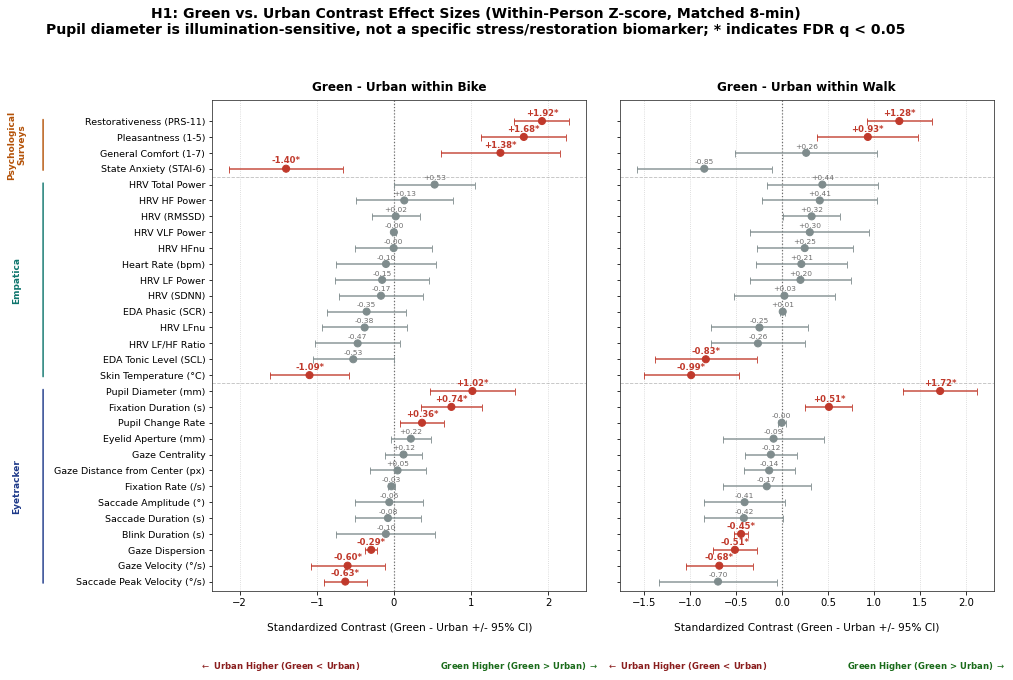

In [4]:
# Figure 1: H1 Green vs Urban (Within-Person Z-score)
h1_wpz = df_wpz[df_wpz["Hypothesis"] == "H1"].copy()
fig1 = plot_forest_contrast(
    h1_wpz, 
    title="H1: Green vs. Urban Contrast Effect Sizes (Within-Person Z-score, Matched 8-min)\nPupil diameter is illumination-sensitive, not a specific stress/restoration biomarker; * indicates FDR q < 0.05",
    xlabel="Standardized Contrast (Green - Urban +/- 95% CI)",
    contrast_col="Contrast",
    figsize=(15, 10)
)
plt.show()




## Figure 2: H2 Psychological–Physiological Concurrence

Person-mean-centered linear mixed models evaluating within-person correspondence between momentary subjective states (Comfort, Pleasantness, Anxiety, Restorativeness) and autonomic/ocular stress reactivity (*Van Doren et al. 2021; Cuve et al. 2023*).


C:\Users\pandya\AppData\Local\Temp\ipykernel_48480\3874292497.py:206: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  fig.tight_layout(rect=[0.11, 0.04, 0.99, 0.95])


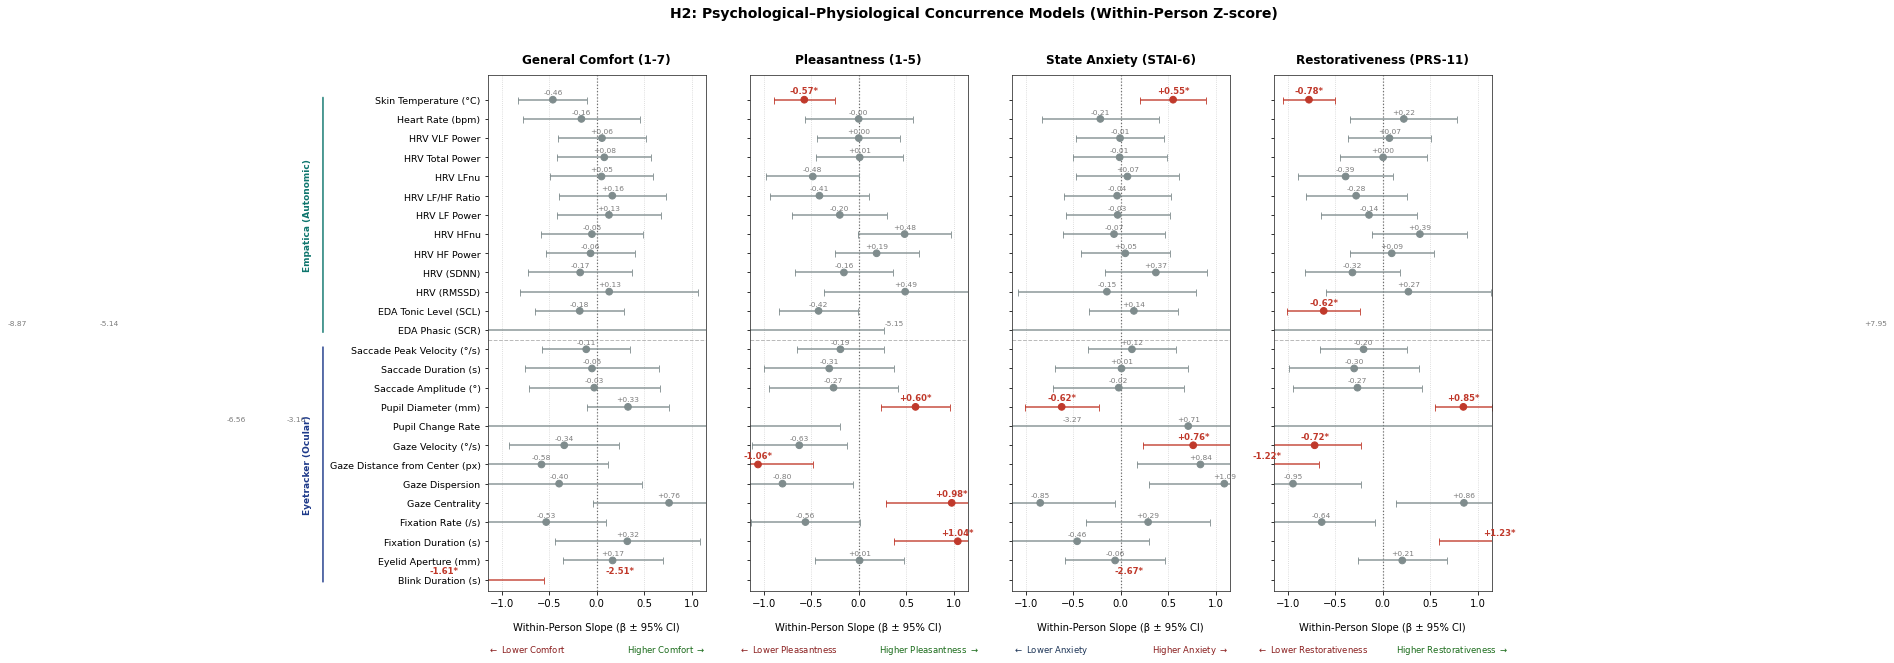

In [5]:
# Figure 2: H2 Concurrence
h2_wpz = df_wpz[df_wpz["Hypothesis"] == "H2"].copy()
fig2 = plot_h2_concurrence(
    h2_wpz,
    title="H2: Psychological–Physiological Concurrence Models (Within-Person Z-score)",
    figsize=(18, 9.5)
)
plt.show()


## Figure 3: H3 Travel Mode Contrasts (Walk vs. Bike)

Evaluates thermal regulation, cardiovascular strain, and visual gaze strategies between Walk and Bike travel in urban corridors and green parks.


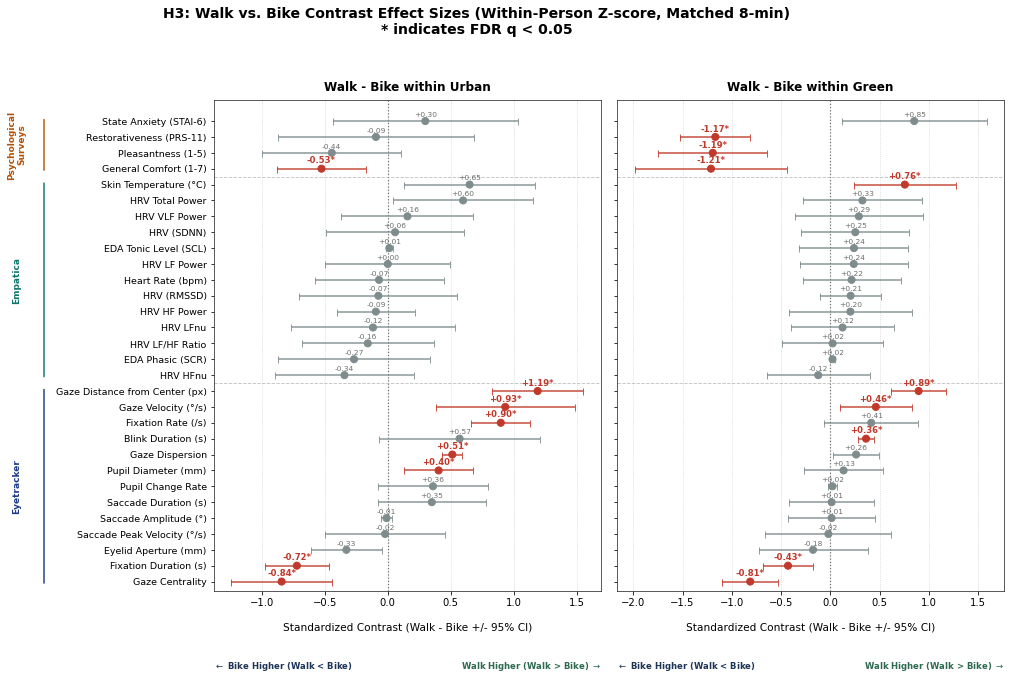

In [6]:
# Figure 3: H3 Walk vs Bike
h3_wpz = df_wpz[df_wpz["Hypothesis"] == "H3"].copy()
fig3 = plot_forest_contrast(
    h3_wpz,
    title="H3: Walk vs. Bike Contrast Effect Sizes (Within-Person Z-score, Matched 8-min)\n* indicates FDR q < 0.05",
    xlabel="Standardized Contrast (Walk - Bike +/- 95% CI)",
    contrast_col="Contrast",
    figsize=(15, 10)
)
plt.show()




## Figure 4: H4 Multivariable 5-Domain Co-Exposure Linear Mixed Model

Definitive multivariable co-exposure linear mixed model evaluating the 5 representative environmental exposure domains (acceptable multicollinearity, all VIF < 3.5) (Thermal: UTCI, Acoustic: Sound Level, Air Quality: PM2.5, Lighting: Illuminance, and Visual Greenery: GVI) simultaneously with travel mode control. Univariate screening tests are omitted in favor of this definitive mutually-adjusted co-exposure model.

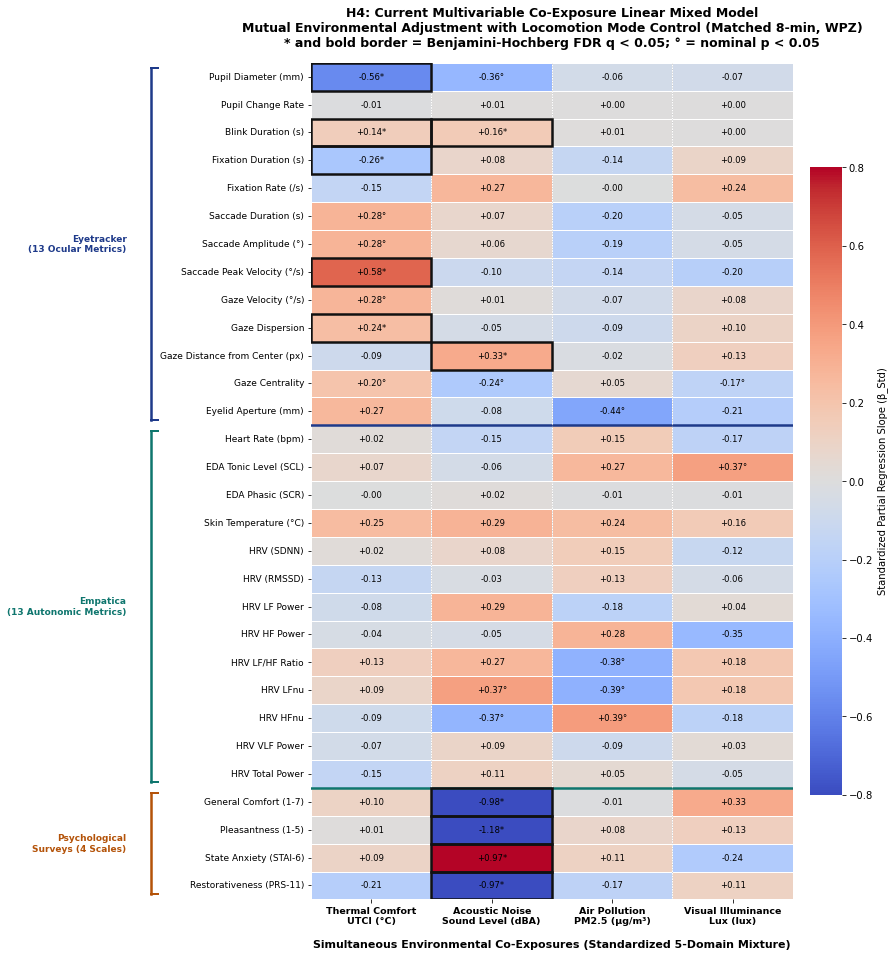

In [7]:
# Figure 4: H4 current multivariable co-exposure heatmap
fig4 = plot_h4_multivariable_heatmap(
    df_h4_multi,
    title="H4: Current Multivariable Co-Exposure Linear Mixed Model\nMutual Environmental Adjustment with Locomotion Mode Control (Matched 8-min, WPZ)\n* and bold border = Benjamini-Hochberg FDR q < 0.05; ° = nominal p < 0.05",
    figsize=(12, 14)
)
plt.show()


## Figure 5: Manuscript Synthesis (H1, H3, and H4)

A 3-panel manuscript summary illustrating key autonomic and ocular markers across Green vs. Urban (H1), Walk vs. Bike (H3), and UTCI-related thermal exposure (H4).


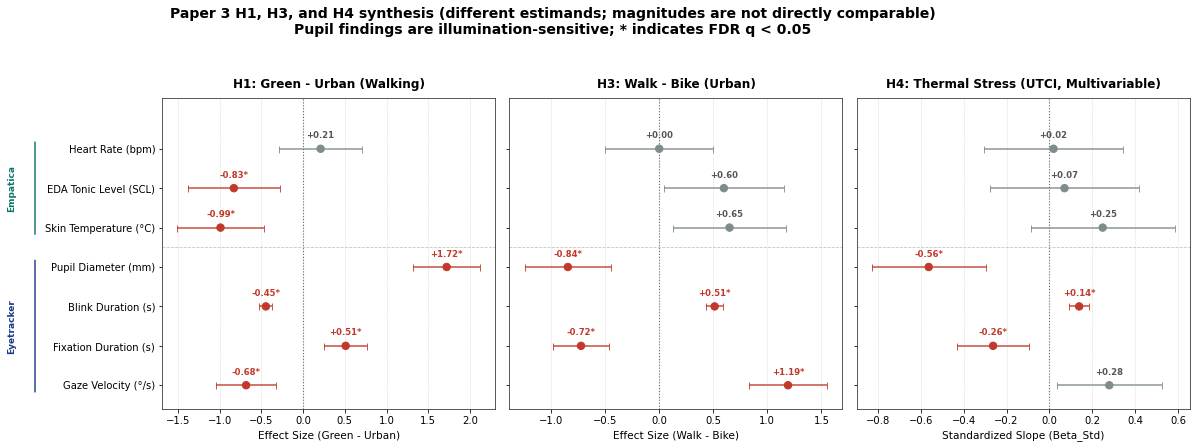

In [8]:
# Figure 5: Manuscript Synthesis
overview_outcomes = [
    "empatica_heart_rate",
    "empatica_eda_tonic",
    "empatica_skin_temperature",
    "eyetracker_pupil_diameter_avg",
    "eyetracker_blink_duration_s",
    "eyetracker_fixation_duration_s",
    "eyetracker_gaze_velocity",
]

sub_h1 = h1_wpz[(h1_wpz["Contrast"] == "Green - Urban within Walk") & (h1_wpz["Outcome"].isin(overview_outcomes))].copy()
sub_h3 = h3_wpz[(h3_wpz["Contrast"] == "Walk - Bike within Urban") & (h3_wpz["Outcome"].isin(overview_outcomes))].copy()
sub_h4 = df_h4_multi[(df_h4_multi["Predictor"] == "ucm_UTCI") & (df_h4_multi["Outcome"].isin(overview_outcomes))].copy()

fig5, axes = plt.subplots(1, 3, figsize=(18, 6.5), sharey=True)
panels = [
    (axes[0], sub_h1, "Estimate_SD", "H1: Green - Urban (Walking)", "Effect Size (Green - Urban)"),
    (axes[1], sub_h3, "Estimate_SD", "H3: Walk - Bike (Urban)", "Effect Size (Walk - Bike)"),
    (axes[2], sub_h4, "Beta_Std", "H4: Thermal Stress (UTCI, Multivariable)", "Standardized Slope (Beta_Std)"),
]

for idx_panel, (ax, data, val_col, ptitle, xlbl) in enumerate(panels):
    data["sort_idx"] = data["Outcome"].map(lambda x: overview_outcomes.index(x) if x in overview_outcomes else 99)
    data["Sensor_Rank"] = data["Outcome"].map(lambda x: get_sensor_group(x)[0])
    data = data.sort_values("sort_idx", ascending=False).reset_index(drop=True)
    
    y_pos = np.arange(len(data))
    colors = [COLOR_SIG if s else COLOR_NS for s in data["is_sig"]]
    ci_low, ci_high = _ci_bounds(data, val_col)
    
    # Dotted zero reference line
    ax.axvline(0, color="#555555", linestyle=":", linewidth=1.1, alpha=0.85)
    for idx in range(len(data) - 1):
        if data.loc[idx, "Sensor_Rank"] != data.loc[idx + 1, "Sensor_Rank"]:
            ax.axhline(idx + 0.5, color="#aaaaaa", linestyle="--", linewidth=0.8, alpha=0.7)
    for xp, yp, c, lo, hi in zip(data[val_col], y_pos, colors, ci_low, ci_high):
        ax.errorbar(xp, yp, xerr=[[xp - lo], [hi - xp]], fmt="none", ecolor=c, elinewidth=1.6, capsize=3.5, alpha=0.85)
    ax.scatter(data[val_col], y_pos, color=colors, s=55, zorder=3)
    
    # Values float cleanly above points to avoid CI bar overlap
    for y, b, sig in zip(y_pos, data[val_col], data["is_sig"]):
        lbl = f"{b:+.2f}*" if sig else f"{b:+.2f}"
        ax.text(b, y + 0.22, lbl, va="bottom", ha="center",
                fontsize=8.5, fontweight="bold", color=COLOR_SIG if sig else "#555555")
        
    ax.set_yticks(y_pos)
    ax.set_yticklabels(data["Outcome"].map(lambda x: LABEL_MAP.get(x, x)), fontsize=10)
    ax.set_ylim(-0.6, len(data) - 0.2 + 0.5)
    ax.set_title(ptitle, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel(xlbl, fontsize=10.5)
    ax.grid(axis="x", linestyle=":", alpha=0.6)

fig5.suptitle("Paper 3 H1, H3, and H4 synthesis (different estimands; magnitudes are not directly comparable)\nPupil findings are illumination-sensitive; * indicates FDR q < 0.05", fontsize=14, fontweight="bold", y=0.98)
fig5.tight_layout(rect=[0.10, 0.03, 1, 0.94])
fig5.canvas.draw()
renderer = fig5.canvas.get_renderer()

# Add domain brackets to leftmost panel
ax0 = axes[0]
min_x_axes = 0.0
for label in ax0.get_yticklabels():
    bbox = label.get_window_extent(renderer=renderer)
    inv = ax0.transAxes.inverted().transform(bbox)
    if inv[0, 0] < min_x_axes:
        min_x_axes = inv[0, 0]
bracket_x = min_x_axes - 0.03
label_x   = bracket_x - 0.07

d0 = sub_h1.sort_values("sort_idx", ascending=False).reset_index(drop=True)
groups = [
    (0, "Eyetracker", "#1e3a8a"),
    (1, "Empatica", "#0f766e")
]
add_sensor_group_labels(ax0, d0, bracket_x=bracket_x, label_x=label_x, font_size=9, groups=groups)
plt.show()





Text(0.5, 1.0, 'Paper 3 field-experiment phases and matched primary analysis window')

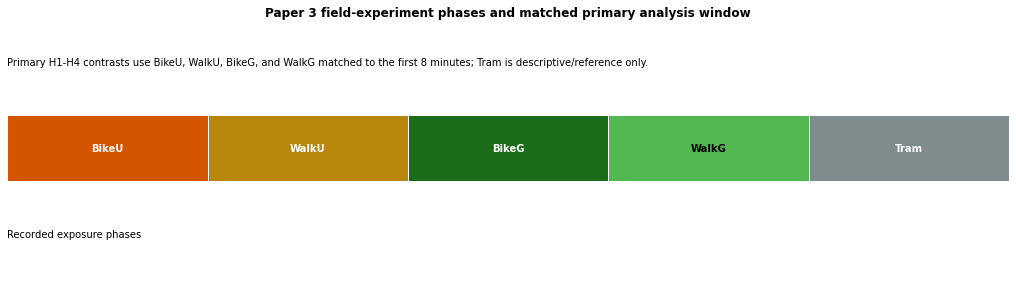

In [9]:
# Figure 6: Study design and matched exposure timeline
# Tram is retained as a recorded descriptive/reference phase; H1-H4 primary contrasts use the four route phases.
PHASE_DISPLAY = ["BikeU", "WalkU", "BikeG", "WalkG", "Tram"]
fig6, ax = plt.subplots(figsize=(14, 3.8), constrained_layout=True)
for i, phase in enumerate(PHASE_DISPLAY):
    ax.barh(0, 1, left=i, height=0.42, color=PHASE_COLORS[phase], edgecolor="white")
    ax.text(i + 0.5, 0, phase, ha="center", va="center", color="white" if phase != "WalkG" else "black", fontweight="bold")
ax.text(0, -0.55, "Recorded exposure phases", ha="left", va="center", fontsize=10)
ax.text(0, 0.55, "Primary H1-H4 contrasts use BikeU, WalkU, BikeG, and WalkG matched to the first 8 minutes; Tram is descriptive/reference only.", ha="left", va="center", fontsize=10)
ax.set_xlim(0, len(PHASE_DISPLAY)); ax.set_ylim(-0.8, 0.8); ax.axis("off")
ax.set_title("Paper 3 field-experiment phases and matched primary analysis window", fontweight="bold")


## Figure 10: Statistical Analysis Workflow

A reproducible flowchart of the primary matched-duration, within-person z-score analysis.


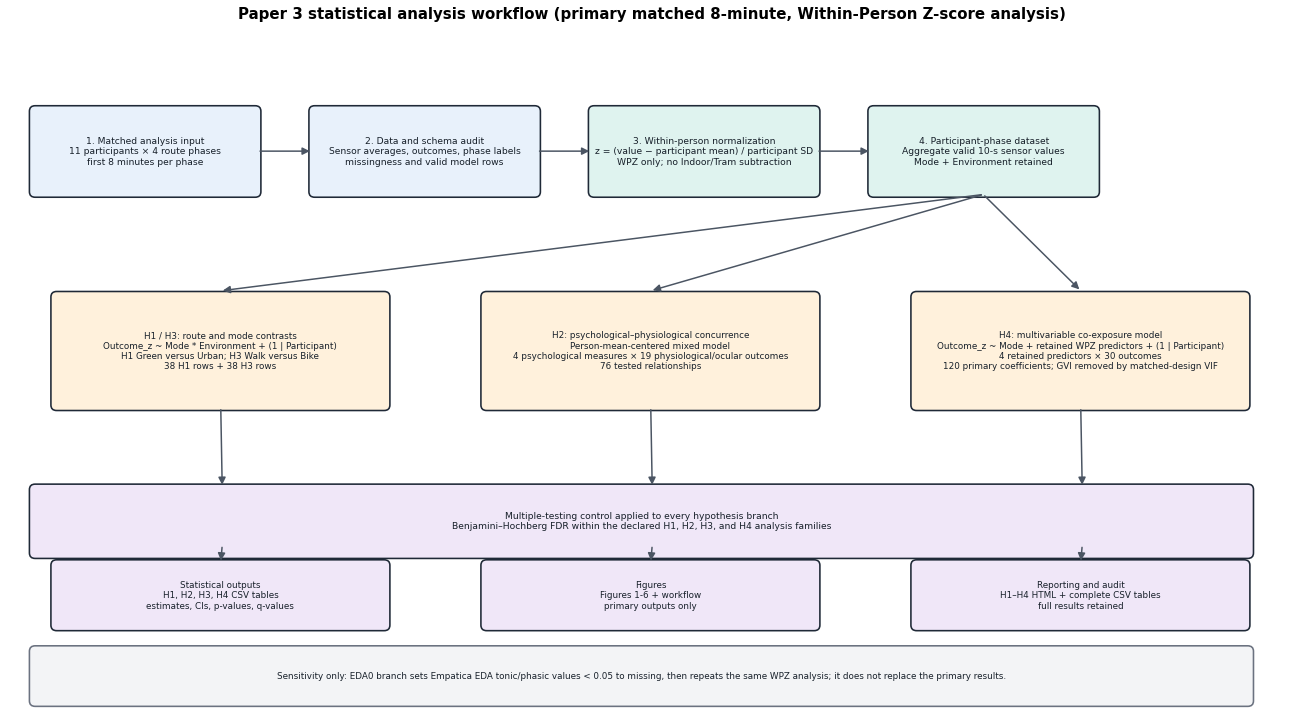

In [10]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def _workflow_box(ax, x, y, w, h, text, face, edge="#1f2937", fontsize=9.2):
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.08",
                         facecolor=face, edgecolor=edge, linewidth=1.6)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=fontsize, color="#17202a", wrap=True)

def _workflow_arrow(ax, x1, y1, x2, y2, dashed=False):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                                 mutation_scale=15, linewidth=1.5,
                                 linestyle="--" if dashed else "-",
                                 color="#4b5563"))

h4_primary = df_wpz[df_wpz["Hypothesis"] == "H4"]
h4_predictor_count = h4_primary["Predictor"].nunique()
h4_model_count = len(h4_primary)

fig10, ax = plt.subplots(figsize=(18, 10), constrained_layout=True)
ax.set_xlim(0, 18); ax.set_ylim(0, 10); ax.axis("off")

# Primary processing chain
top = [
    (0.35, 7.65, 3.15, 1.25, "1. Matched analysis input\n11 participants × 4 route phases\nfirst 8 minutes per phase", "#e8f1fb"),
    (4.25, 7.65, 3.15, 1.25, "2. Data and schema audit\nSensor averages, outcomes, phase labels\nmissingness and valid model rows", "#e8f1fb"),
    (8.15, 7.65, 3.15, 1.25, "3. Within-person normalization\nz = (value − participant mean) / participant SD\nWPZ only; no Indoor/Tram subtraction", "#dff3ef"),
    (12.05, 7.65, 3.15, 1.25, "4. Participant-phase dataset\nAggregate valid 10-s sensor values\nMode + Environment retained", "#dff3ef"),
]
for item in top: _workflow_box(ax, *item)
for x in [3.5, 7.4, 11.3]: _workflow_arrow(ax, x, 8.28, x + 0.75, 8.28)

# Hypothesis branches
branches = [
    (0.65, 4.55, 4.65, 1.65, f"H1 / H3: route and mode contrasts\nOutcome_z ~ Mode * Environment + (1 | Participant)\nH1 Green versus Urban; H3 Walk versus Bike\n38 H1 rows + 38 H3 rows", "#fff1dc"),
    (6.65, 4.55, 4.65, 1.65, f"H2: psychological–physiological concurrence\nPerson-mean-centered mixed model\n4 psychological measures × 19 physiological/ocular outcomes\n76 tested relationships", "#fff1dc"),
    (12.65, 4.55, 4.65, 1.65, f"H4: multivariable co-exposure model\nOutcome_z ~ Mode + retained WPZ predictors + (1 | Participant)\n{h4_multi_predictor_count} retained predictors × 30 outcomes\n{h4_multi_model_count} primary coefficients; GVI removed by matched-design VIF", "#fff1dc"),
]
for item in branches: _workflow_box(ax, *item, fontsize=8.8)
_workflow_arrow(ax, 13.62, 7.65, 2.98, 6.25)
_workflow_arrow(ax, 13.62, 7.65, 8.98, 6.25)
_workflow_arrow(ax, 13.62, 7.65, 14.98, 6.25)

# Correction and deliverables
_workflow_box(ax, 0.35, 2.4, 17.0, 1.0, "Multiple-testing control applied to every hypothesis branch\nBenjamini–Hochberg FDR within the declared H1, H2, H3, and H4 analysis families", "#f0e7f8")
_workflow_box(ax, 0.65, 1.35, 4.65, 0.95, "Statistical outputs\nH1, H2, H3, H4 CSV tables\nestimates, CIs, p-values, q-values", "#f0e7f8", fontsize=8.8)
_workflow_box(ax, 6.65, 1.35, 4.65, 0.95, "Figures\nFigures 1-6 + workflow\nprimary outputs only", "#f0e7f8", fontsize=8.8)
_workflow_box(ax, 12.65, 1.35, 4.65, 0.95, "Reporting and audit\nH1–H4 HTML + complete CSV tables\nfull results retained", "#f0e7f8", fontsize=8.8)
for x1, x2 in [(2.98, 3.0), (8.98, 9.0), (14.98, 15.0)]:
    _workflow_arrow(ax, x1, 4.55, x2, 3.4)
for x1, x2 in [(3.0, 2.98), (9.0, 8.98), (15.0, 14.98)]:
    _workflow_arrow(ax, x1, 2.55, x2, 2.3)

# Sensitivity branch is shown separately so it is not confused with the primary analysis.
_workflow_box(ax, 0.35, 0.25, 17.0, 0.8,
              "Sensitivity only: EDA0 branch sets Empatica EDA tonic/phasic values < 0.05 to missing, then repeats the same WPZ analysis; it does not replace the primary results.",
              "#f3f4f6", edge="#6b7280", fontsize=8.8)
ax.set_title("Paper 3 statistical analysis workflow (primary matched 8-minute, Within-Person Z-score analysis)",
             fontsize=15, fontweight="bold", pad=14)
plt.show()


## Final Layer: Export High-Resolution Figures (300 DPI)

Saves all figures into `output/Figures/` in a single consolidated save operation.


In [11]:
# =============================================================================
# LAYER 4: SAVE CELL -- EXPORT ALL FIGURES
# =============================================================================
import time

figs = [
    (fig1, "Figure1_H1_Green_vs_Urban_ForestPlot.png"),
    (fig2, "Figure2_H2_Psych_Physio_Concurrence.png"),
    (fig3, "Figure3_H3_Walk_vs_Bike_ForestPlot.png"),
    (fig4, "Figure4_H4_Multivariable_CoExposure_Heatmap.png"),
    (fig5, "Figure5_H1_H3_H4_Manuscript_Synthesis.png"),
    (fig6, "Figure6_Study_Design_Timeline.png"),
    (fig10, "Figure10_Statistical_Analysis_Workflow.png"),
]

for f, name in figs:
    out_file = OUT_DIR / name
    saved = False
    for attempt in range(3):
        try:
            f.savefig(out_file, dpi=300, bbox_inches="tight")
            saved = True
            break
        except Exception as err:
            time.sleep(1.0)
    if not saved:
        try:
            f.savefig(out_file, dpi=300)
        except Exception as e:
            print(f"Warning: Could not save {name}: {e}")

print("SUCCESS: All publication figures exported to:")
for f in sorted(OUT_DIR.glob("*.png")):
    print(" -", f.name)




SUCCESS: All publication figures exported to:
 - Figure10_Statistical_Analysis_Workflow.png
 - Figure1_H1_Green_vs_Urban_ForestPlot.png
 - Figure2_H2_Psych_Physio_Concurrence.png
 - Figure3_H3_Walk_vs_Bike_ForestPlot.png
 - Figure4_H4_Multivariable_CoExposure_Heatmap.png
 - Figure5_H1_H3_H4_Manuscript_Synthesis.png
 - Figure6_Study_Design_Timeline.png
